# 2. Pretraining, training and niches

This vignette runs the default GRASS-MIL path on the tiles of vignette 1:

1. label-free pretraining of the ego-graph encoder (BGRL);
2. fine-tuning with the default regime (`finetune`), on one image for training,
   one for validation and one for testing;
3. per-cell outputs of the trained model;
4. niche discovery: which neighbourhoods the model relies on, and how they look.

Everything runs on a CPU; the step counts are small to keep it to a few minutes.

In [1]:
import json
import pathlib
import subprocess

import pandas as pd
from IPython.display import Image, Markdown, display

WORK = pathlib.Path("vignette_work").resolve()
DATA = WORK / "data"
COHORT = json.loads((WORK / "cohort.json").read_text())  # written by vignette 1

# Fine-tuning on a handful of tiles: a stronger probe penalty (the default C=1
# suits tens of thousands of ego-graphs) and more optimizer steps per epoch.
SMALL_DATA = ["finetune.probe.C=0.01", "finetune.hyperbatch_size=4"]


def run(command, *overrides):
    """Run a grass-mil command; show the end of its log if it fails.

    Commands that read the cohort (train, nested-cv, extract) get its settings;
    the analysis commands read a cell cache instead.
    """
    cohort = COHORT["overrides"] if command in ("grass-mil-train", "grass-mil-nested-cv", "grass-mil-extract") else []
    result = subprocess.run([command, *cohort, *overrides], capture_output=True, text=True)
    if result.returncode:
        print(result.stderr[-4000:])
        raise RuntimeError(f"{command} failed")

## 1. Pretraining

`regime=pretrain` trains the encoder on the ego-graphs of every cell, without
labels: two augmented views of each ego-graph should embed alike. A real cohort
uses the default 200,000 steps; 3,000 are enough here (a few minutes on a GPU,
about ten on a CPU). Too short a pretraining leaves the embeddings nearly
constant, and the probe head fitted on them in the next step then starts from
very large logits.

In [2]:
import torch

run(
    "grass-mil-train",
    "regime=pretrain",
    "pretrain.total_steps=3000",
    "pretrain.warmup_steps=100",
    "callbacks.model_checkpoint.every_n_train_steps=1000",
    "trainer=gpu" if torch.cuda.is_available() else "trainer=cpu",
    f"hydra.run.dir={WORK / 'pretrain'}",
)
ENCODER = WORK / "pretrain" / "checkpoints" / "last.ckpt"
print(ENCODER.relative_to(WORK.parent))

vignette_work/pretrain/checkpoints/last.ckpt


## 2. Fine-tuning

The default regime fine-tunes the pretrained encoder end to end. The linear
instance head is first fitted as a logistic probe on the frozen embeddings, and
the attention learns which cells of a tile to weight. Each image is one split.
With 16 training tiles, `SMALL_DATA` regularises the probe more strongly and
takes an optimizer step every 4 tiles instead of 12.

In [3]:
train_image, val_image, test_image = sorted(pd.read_csv(DATA / "labels.csv")["image"].unique())
run(
    "grass-mil-train",
    f"model.init_from_ckpt={ENCODER}",
    *SMALL_DATA,
    f"data.split.train=[{train_image}]",
    f"data.split.val=[{val_image}]",
    f"data.split.test=[{test_image}]",
    "trainer.max_epochs=20",
    "trainer.min_epochs=5",
    f"hydra.run.dir={WORK / 'train'}",
)
metrics = pd.read_json(WORK / "train" / "metrics_per_epoch.jsonl", lines=True)
display(metrics[["epoch", "train/loss_epoch", "val/loss", "val/auroc"]].round(3).tail())
pd.read_csv(WORK / "train" / "test_predictions.csv").round(3).head()

,epoch,train/loss_epoch,val/loss,val/auroc
10,10,0.565,3.868,0.714
11,11,0.134,2.663,0.714
12,12,0.233,1.448,0.714
13,13,0.410,3.618,0.743
14,14,0.171,3.988,0.743


,unit_id,prob_0,prob_1,pred,label,region_id,sample_id,patient_id
0,point8_tile000,0.228,0.772,1,0,point8,point8,point8
1,point8_tile001,0.995,0.005,0,0,point8,point8,point8
2,point8_tile002,0.926,0.074,0,0,point8,point8,point8
3,point8_tile003,0.920,0.080,0,0,point8,point8,point8
4,point8_tile004,0.644,0.356,0,0,point8,point8,point8


## 3. Per-cell outputs

`grass-mil-extract` rebuilds the model from its checkpoint and scores every cell
of every tile: its embedding, its coordinates in the attention head's space,
its instance logits and attention scores.

In [4]:
MODEL = WORK / "train" / "checkpoints" / "last.ckpt"
run(
    "grass-mil-extract",
    f"+extract.models.trained={MODEL}",
    f"extract.output_dir={WORK / 'cells'}",
    f"hydra.run.dir={WORK / 'extract'}",
)

## 4. Niches

`grass-mil-niches` clusters the cells in the model's attention space (cosine
HDBSCAN), numbers the niches by their attention-weighted margin (Niche 1 pushes
the prediction most towards *infiltrated*), and describes each by its
composition, its empirical association (the fraction of its cells from
infiltrated tiles) and the spatial arrangement of its cells. This model saw
every image during training or validation, so all tiles are analysed
(`units=all`); vignette 3 analyses held-out tiles of cross-validation models.
With only 3,300 cells, HDBSCAN's default cluster selection merges almost all
cells into one niche; `clustering.selection=leaf` keeps the finest stable
clusters.

In [5]:
run(
    "grass-mil-niches",
    f"cells_dir={WORK / 'cells' / 'trained'}",
    "units=all",
    "clustering.min_cluster_size=50",
    "clustering.selection=leaf",
    "positive_name=infiltrated",
    f"hydra.run.dir={WORK / 'niches'}",
)
NICHES = WORK / "niches"
display(Markdown((NICHES / "report.md").read_text()))

# Niches of trained

44 units, 3280 cells. Clustering: hdbscan in the attention space (PCA none, cosine True, fitted on 3280 cells, 15-NN assignment): 16 niches. Fraction of cells from infiltrated units: 0.539.

| Niche | Cells | Units (>2%) | Composition | Enriched (>1.5x) | Association | Margin [95% CI] | Sign consistency |
|---|---|---|---|---|---|---|---|
| Niche 1 | 2.1% | 6 | Tcell_CD4 31%, Tcell_CD8 21%, Imm_other 17% | Myeloid_CD11c x2.3, Tcell_CD8 x1.5 | 0.84 | +21.23 [+20.24, +22.29] | 1.00 |
| Niche 2 | 3.5% | 9 | Imm_other 30%, Tcell_CD4 30%, Tcell_CD8 26% | Imm_other x2.1, Tcell_CD8 x1.8 | 0.81 | +19.94 [+18.90, +20.91] | 1.00 |
| Niche 3 | 2.0% | 8 | Tcell_CD4 42%, Imm_other 14%, Tcell_CD8 14% | Endothelial x1.8, Tcell_CD4 x1.7 | 0.61 | +18.44 [+16.66, +20.22] | 1.00 |
| Niche 4 | 1.9% | 8 | Tcell_CD4 52%, Epithelial 11%, Myeloid_CD11c 11% | Myeloid_CD11c x2.2, Tcell_CD4 x2.1 | 0.42 | +16.07 [+14.40, +17.77] | 1.00 |
| Niche 5 | 2.3% | 8 | Tcell_CD4 43%, Myeloid_CD68 16%, Fibroblast 9% | Myeloid_CD68 x2.0, Tcell_CD4 x1.8 | 0.55 | +15.67 [+13.60, +17.79] | 1.00 |
| Niche 6 | 11.0% | 16 | Tcell_CD4 37%, Imm_other 20%, Tcell_CD8 16% | Myeloid_CD11c x1.7, Endothelial x1.6, Tcell_CD4 x1.5 | 0.78 | +13.34 [+11.91, +14.84] | 1.00 |
| Niche 7 | 2.0% | 6 | Tcell_CD4 27%, Imm_other 18%, Fibroblast 16% | Fibroblast x2.0, Myeloid_CD68 x1.5 | 0.84 | +10.47 [+9.90, +11.07] | 1.00 |
| Niche 8 | 4.3% | 10 | Epithelial 62%, Tcell_CD4 16%, Endothelial 5% | Epithelial x2.8 | 0.18 | +9.22 [+8.15, +10.23] | 1.00 |
| Niche 9 | 1.6% | 6 | Tcell_CD4 34%, Imm_other 30%, Tcell_CD8 11% | Endothelial x2.7, Imm_other x2.0, Myeloid_CD11c x1.5 | 0.91 | +7.45 [+6.73, +8.33] | 1.00 |
| Niche 10 | 3.2% | 13 | Epithelial 36%, Myeloid_CD68 17%, Tcell_CD4 17% | Myeloid_CD68 x2.2, Epithelial x1.6 | 0.36 | +7.40 [+6.60, +8.18] | 1.00 |
| Niche 11 | 1.6% | 4 | Epithelial 52%, Tcell_CD4 15%, Tcell_CD8 13% | Epithelial x2.3 | 0.33 | +7.22 [+5.97, +8.46] | 1.00 |
| Niche 12 | 7.6% | 18 | Epithelial 20%, Tcell_CD4 20%, Tcell_CD8 18% | Fibroblast x1.6 | 0.57 | +6.56 [+5.74, +7.41] | 1.00 |
| Niche 13 | 2.7% | 7 | Tcell_CD4 34%, Tcell_CD8 34%, Imm_other 13% | Tcell_CD8 x2.4, Endothelial x2.3 | 0.95 | +5.82 [+5.24, +6.64] | 1.00 |
| Niche 14 | 4.8% | 14 | Epithelial 30%, Myeloid_CD68 19%, Fibroblast 16% | Myeloid_CD68 x2.4, Fibroblast x1.9 | 0.34 | +5.62 [+5.05, +6.16] | 1.00 |
| Niche 15 | 3.2% | 10 | Fibroblast 35%, Myeloid_CD68 23%, Imm_other 14% | Fibroblast x4.3, Myeloid_CD68 x2.9 | 0.44 | +4.66 [+4.24, +5.09] | 1.00 |
| Niche 16 | 2.0% | 7 | Fibroblast 55%, Tcell_CD4 20%, Imm_other 14% | Fibroblast x6.6 | 0.14 | +3.55 [+3.29, +3.81] | 1.00 |
| Background | 44.3% | 44 | Epithelial 29%, Tcell_CD4 21%, Imm_other 15% |  | 0.49 | +9.07 [+7.61, +10.55] | 1.00 |


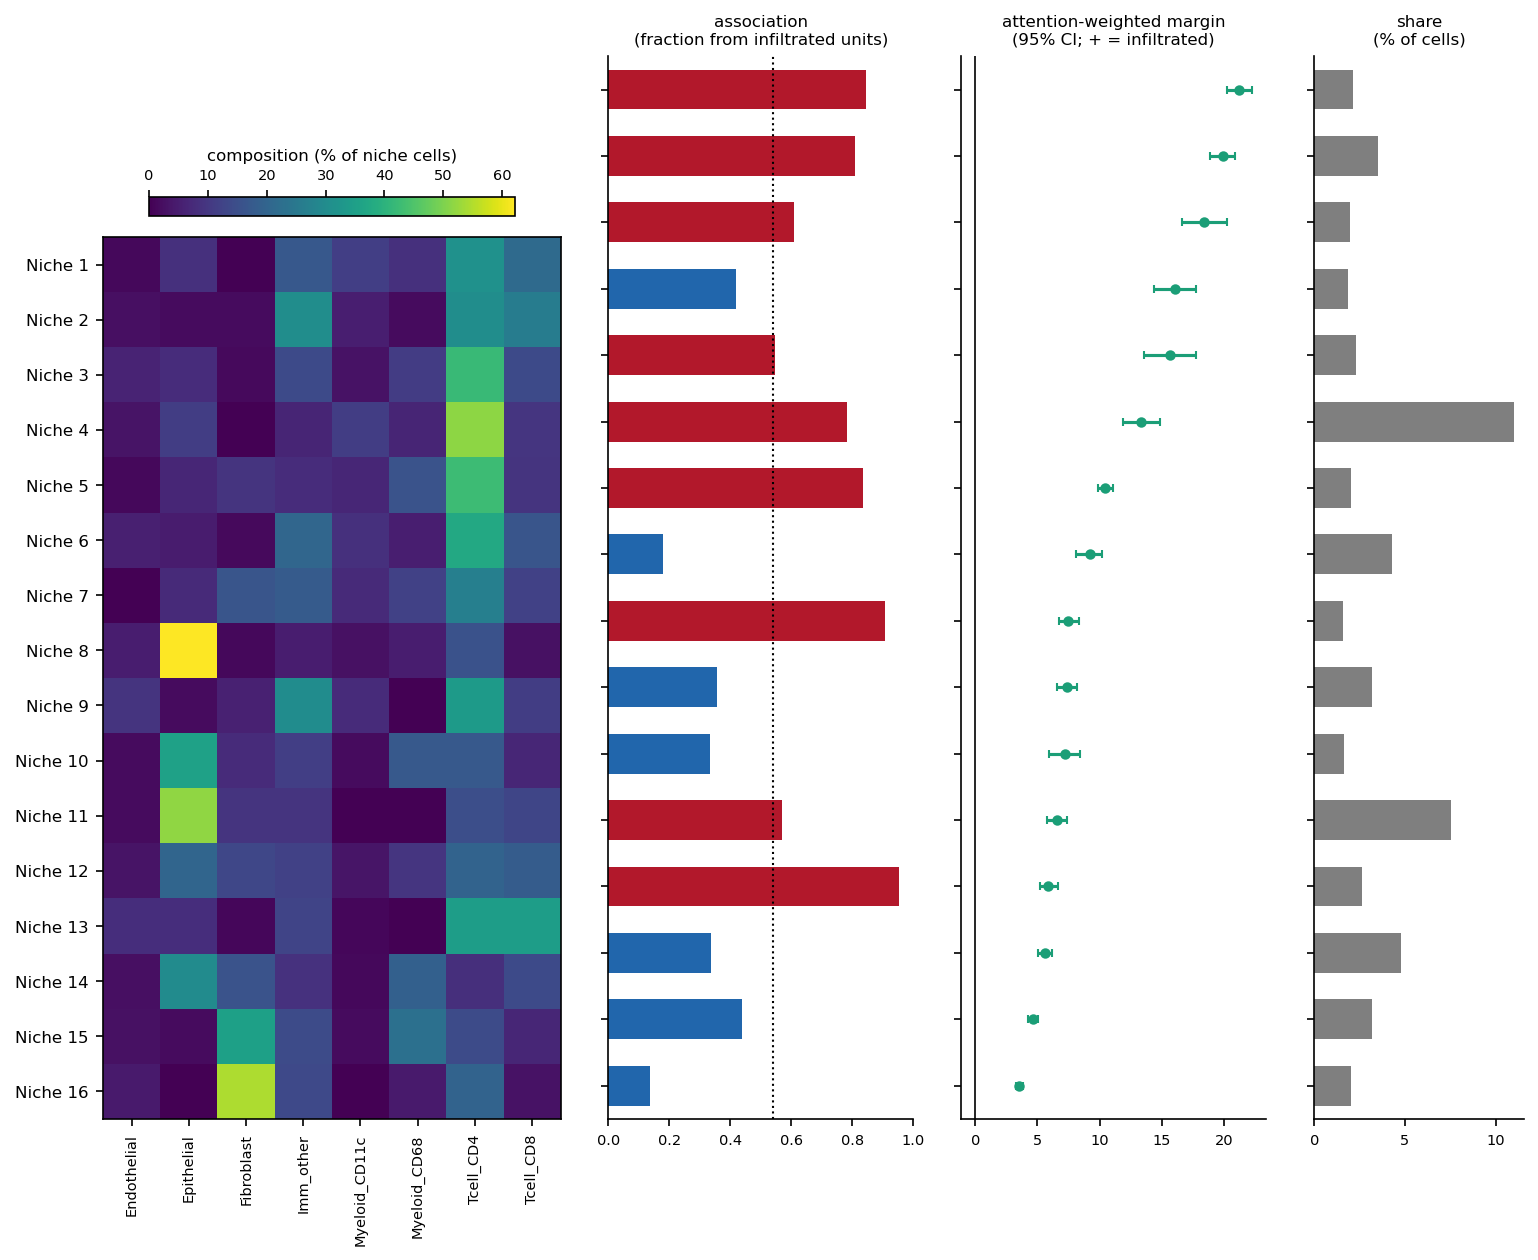

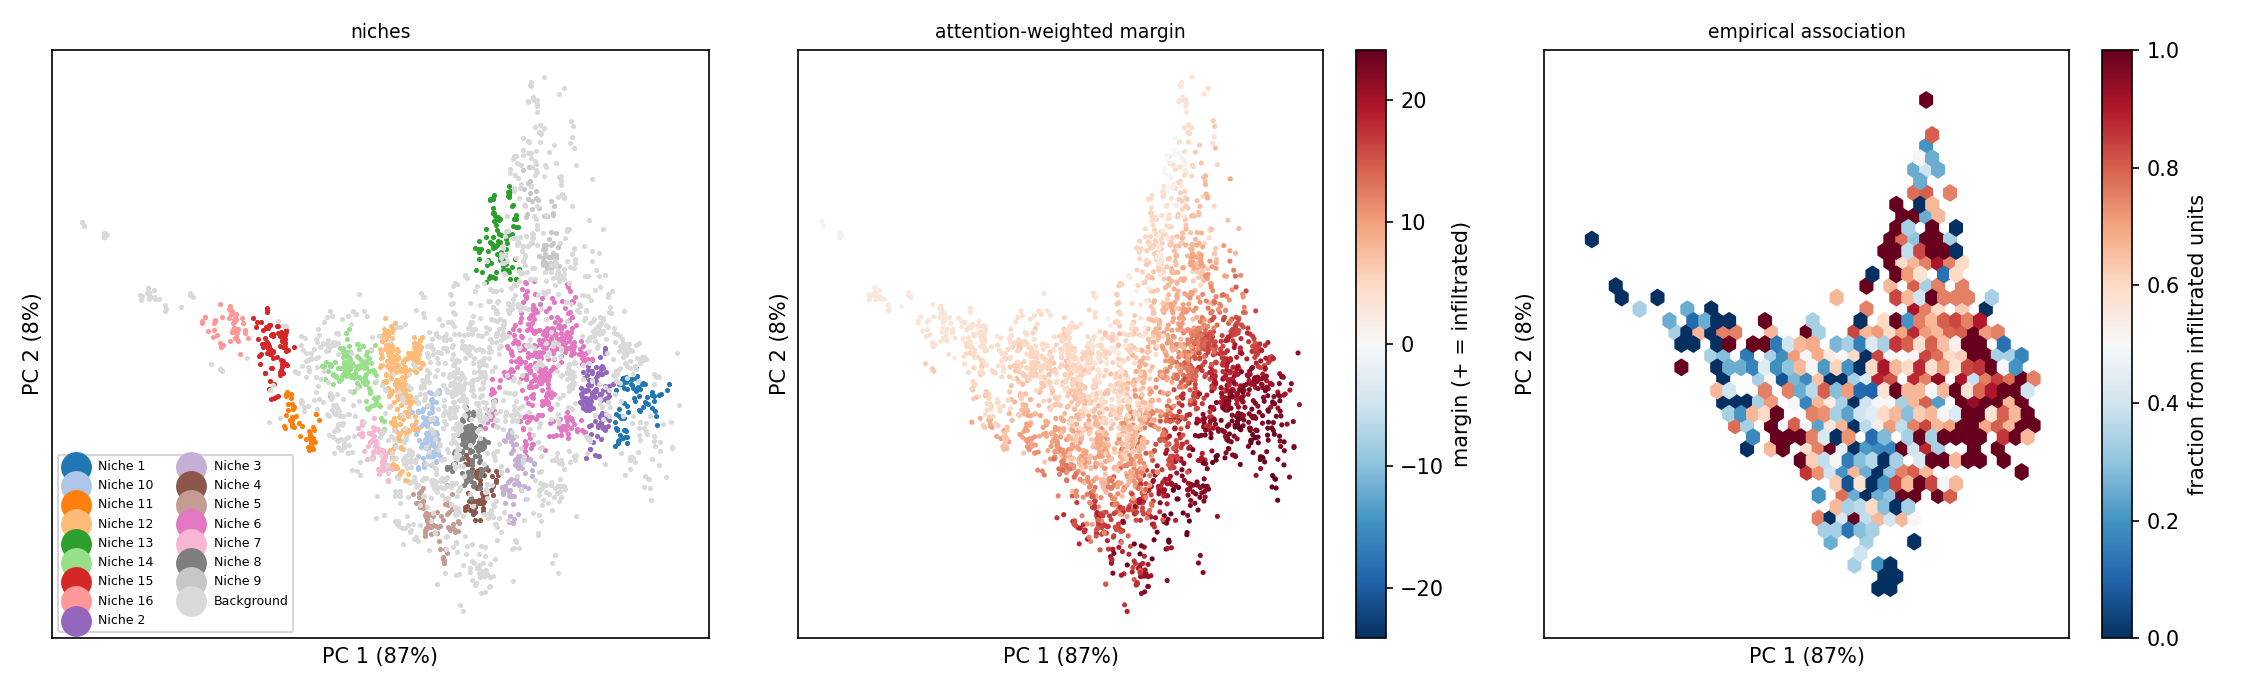

In [6]:
display(Image(NICHES / "figures" / "niche_panel.png"))
display(Image(NICHES / "figures" / "embedding.png"))

The niches the model weights most towards *infiltrated* (top) are T-cell rich
and come mostly from infiltrated tiles; epithelial and fibroblast niches sit at
the bottom. The maps show the most and least infiltrated
tiles as the model sees them: cell types, the margin of every cell and its niche.

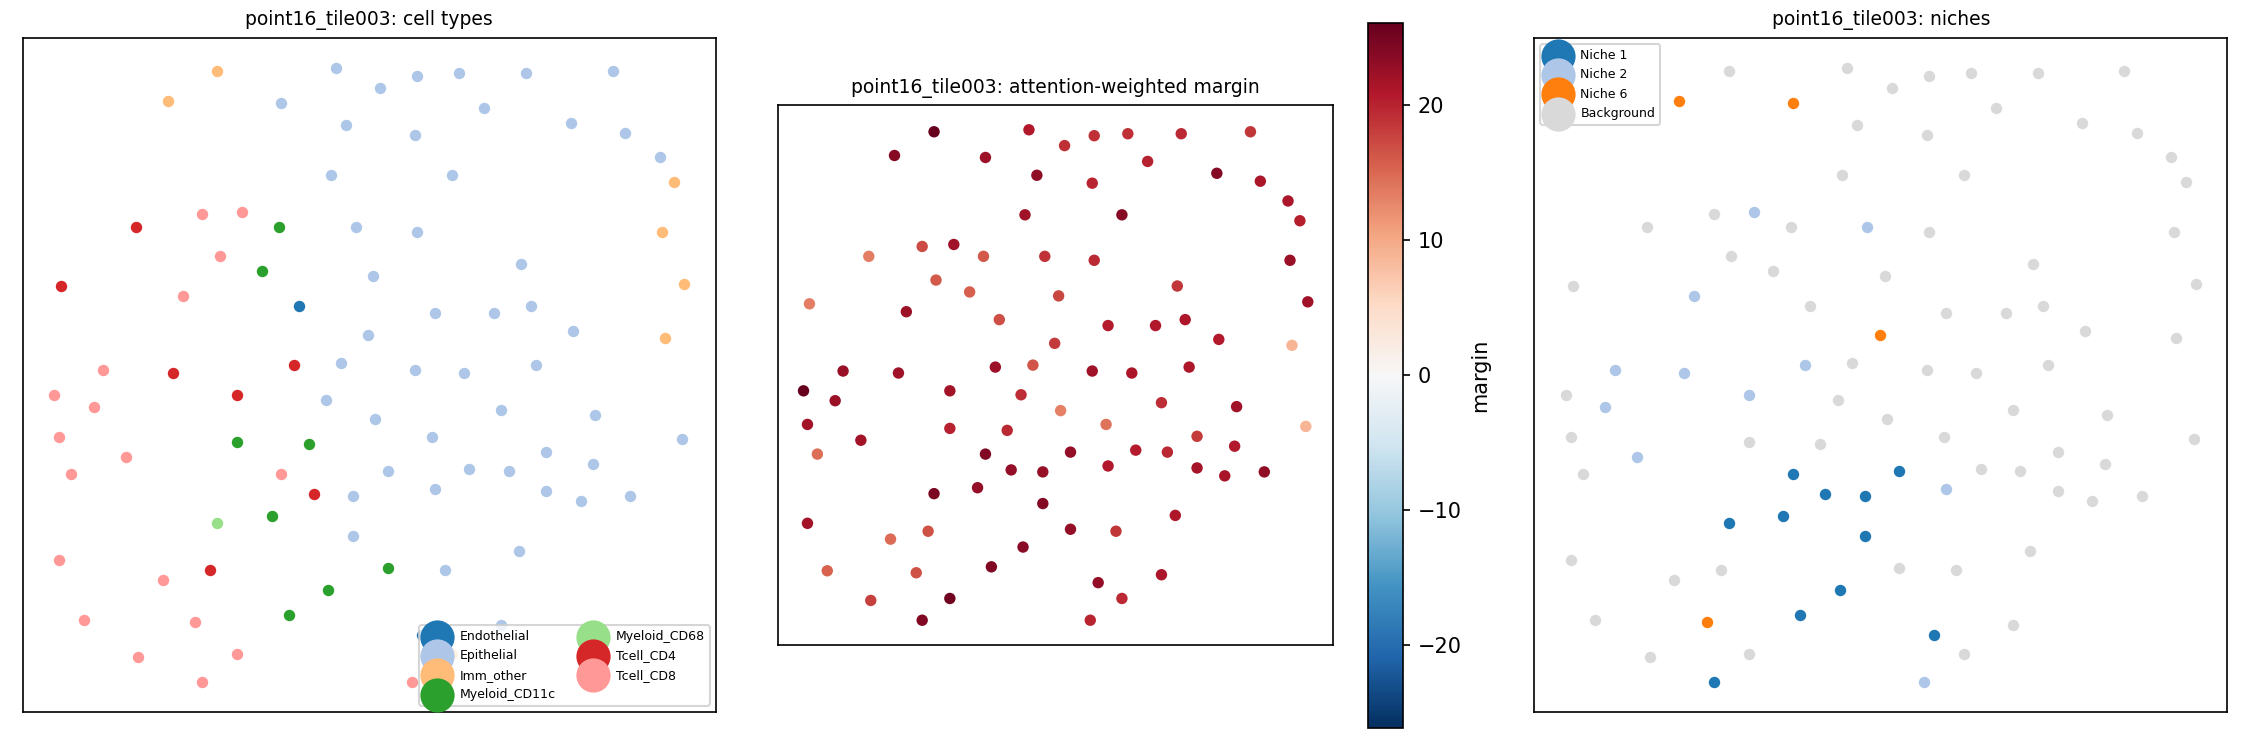

In [7]:
maps = sorted((NICHES / "figures" / "units").glob("*.png"))
display(Image(maps[0]))

Within every niche, classical statistics describe how its cells are arranged:
Moran's I of each cell type, neighbourhood enrichment and cross-L of every
cell-type pair, and contact enrichment relative to the whole tissue.

,niche,cell_type,morans_i,sem,n_units,p,q
5,Niche 2,Imm_other,0.500,NaN,1,0.01,0.069
2,Niche 1,Myeloid_CD68,0.458,NaN,1,0.01,0.069
17,Niche 4,Epithelial,0.448,NaN,1,0.02,0.104
56,Niche 12,Epithelial,0.442,NaN,1,0.01,0.069
67,Niche 13,Tcell_CD8,0.428,0.179,2,0.01,0.069
20,Niche 4,Tcell_CD4,0.397,NaN,1,0.02,0.104
40,Niche 8,Epithelial,0.286,0.058,3,0.01,0.069
65,Niche 13,Imm_other,0.275,0.267,2,0.03,0.139


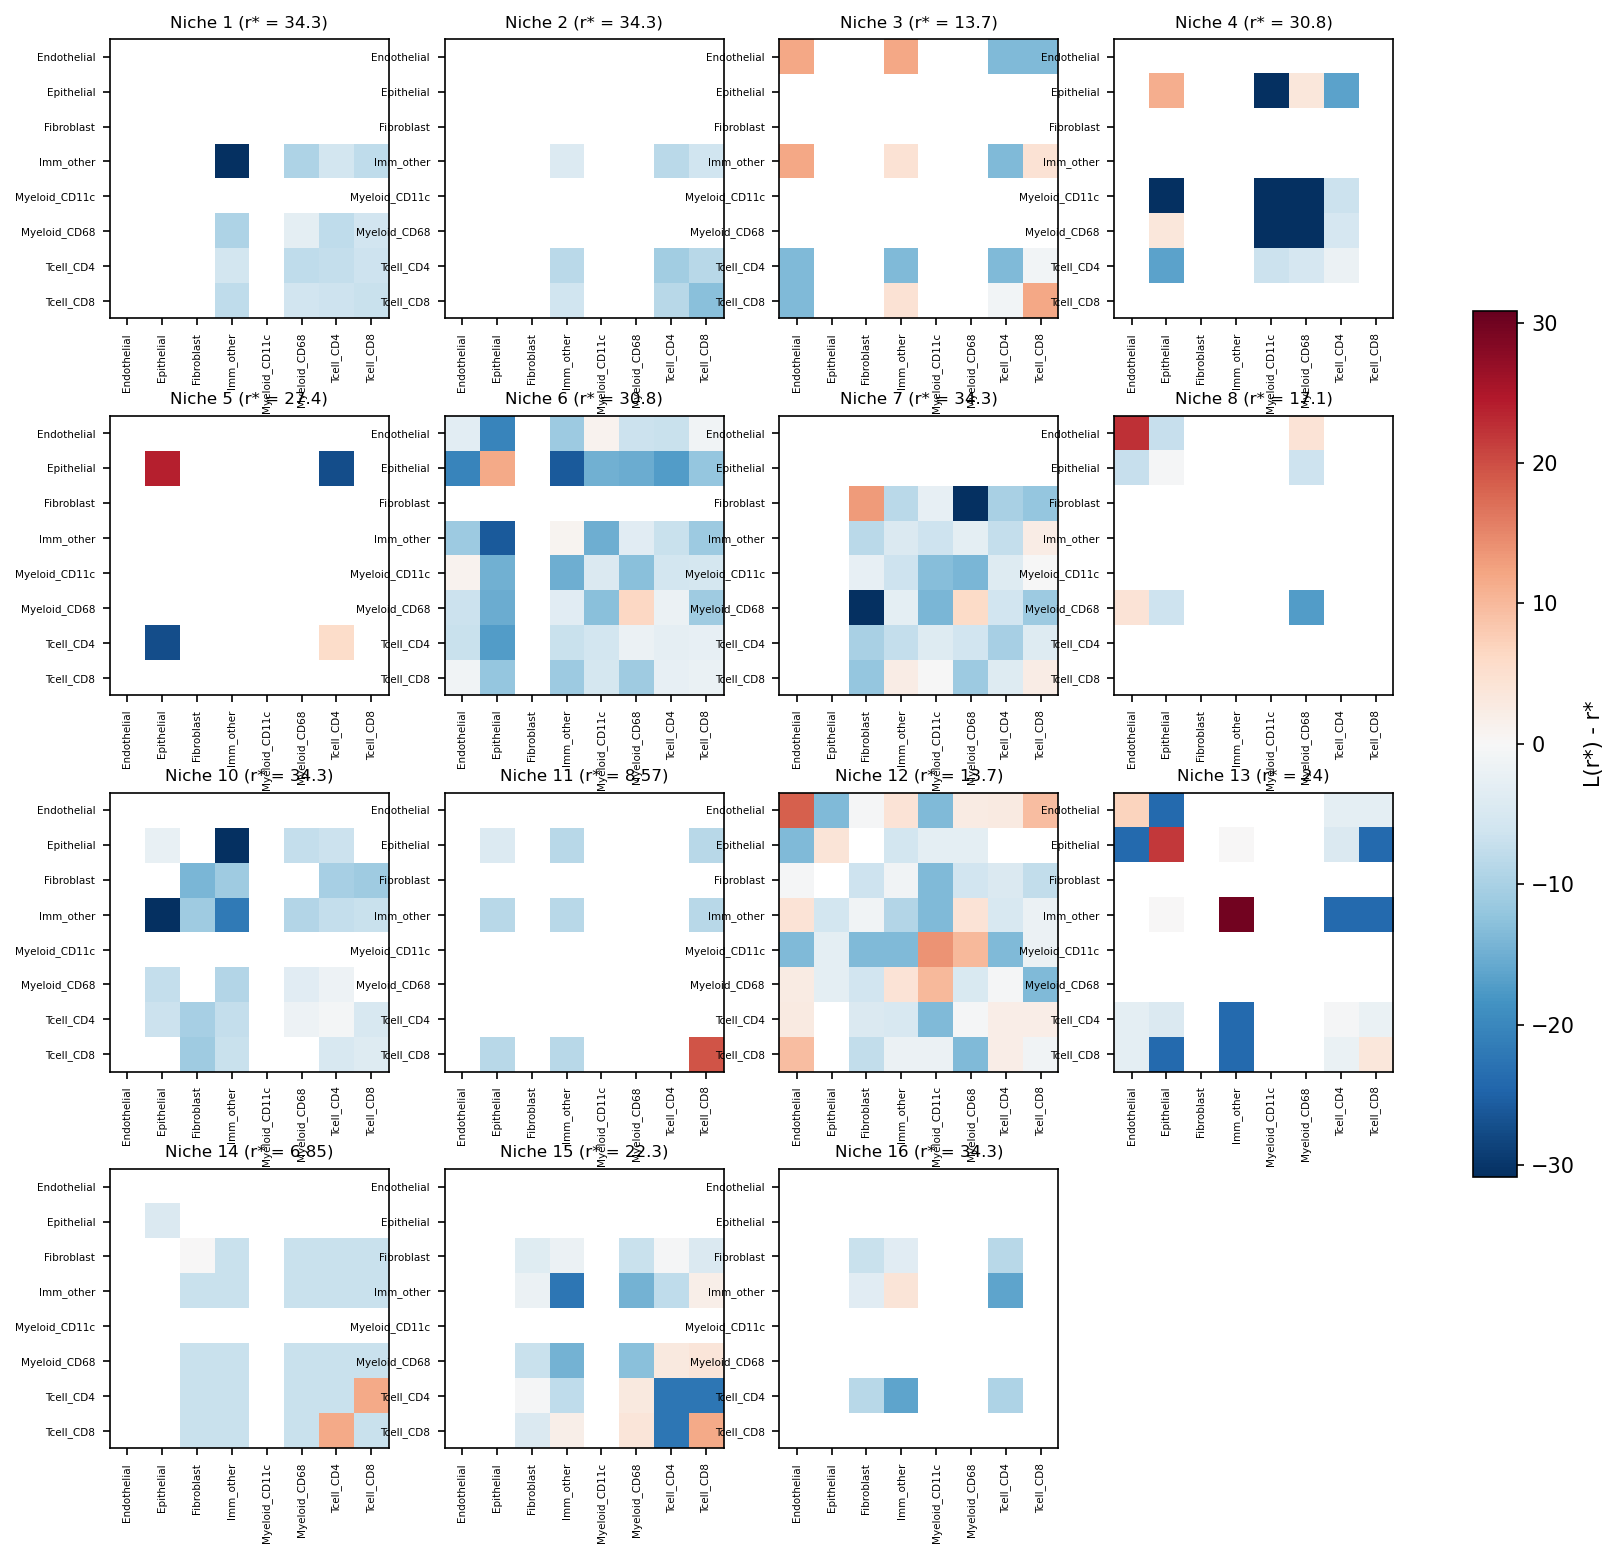

In [8]:
moran = pd.read_csv(NICHES / "descriptors" / "moran.csv")
display(moran.sort_values("morans_i", ascending=False).head(8).round(3))
display(Image(NICHES / "figures" / "cross_l.png"))